# Quantum State Discrimination by Regularized Semidefinite Programming
___

## Problem

Alice draws an index $i$ with probability $p_i$ and sends Bob the state $\rho_i$ over a quantum channel.
Bob knows the ensemble $\{p_i, \rho_i\}_{i=1}^{n}$ but not the draw, and must name $i$ from a single copy of
what arrives. Since the states are not orthogonal in general, no measurement recovers $i$ with certainty,
and the question is how well Bob can do.

Bob's most general strategy is a POVM $\{M_1, \dots, M_n\} \subset \mathbb{H}_{\ge}(\mathcal{H})$ with
$\sum_{i=1}^{n} M_i = \mathrm{I}$, where outcome $i$ is read as the answer "$\rho_i$". By the Born rule the
probability of outcome $i$ given that $\rho_i$ was sent is $\operatorname{Tr}[M_i \rho_i]$, so
$$
\Pr[\text{correct}] \ = \ \sum_{i=1}^{n} \Pr[\rho_i \text{ selected}] \cdot \Pr[\text{outcome } i \mid \rho_i \text{ sent}] \ = \ \sum_{i=1}^{n} p_i \operatorname{Tr}[M_i \rho_i].
$$

**Definition (Quantum state discrimination).** For a finite set of density matrices $\{\rho_i\}_{i=1}^{n}$
on a $d$-dimensional Hilbert space $\mathcal{H}$ with prior probabilities $\{p_i\}_{i=1}^{n}$,
$$
\mathrm{QSD}[\rho_i, p_i] \ := \ \sup\left\{ \sum_{i=1}^{n} p_i \langle \rho_i, M_i \rangle \ : \ \sum_{i=1}^{n} M_i = \mathrm{I}_\mathcal{H}, \ M_i \in \mathbb{H}_{\ge}(\mathcal{H}) \ \forall i \in [n] \right\}.
$$

This is a semidefinite program: the objective is linear in $(M_1, \dots, M_n)$, as well as constraint $\sum_i M_i = \mathrm{I}$, and each $M_i$ ranges over a positive semidefinite cone.

## Dual problem

The only constraint to relax is $\sum_i M_i = \mathrm{I}$. It is one equality *between operators*, so it
carries a single Hermitian multiplier $Z \in \mathbb{H}(\mathcal{H})$ — not one per state — and the
Lagrangian is
$$
\mathcal{L}(M, Z) \ = \ \sum_{i=1}^{n} p_i \langle \rho_i, M_i \rangle \ + \ \Bigl\langle Z, \ \mathrm{I} - \sum_{i=1}^{n} M_i \Bigr\rangle \ = \ \operatorname{Tr}[Z] \ + \ \sum_{i=1}^{n} \langle p_i \rho_i - Z, \ M_i \rangle .
$$
Its supremum over $M_i \succeq 0$ is $+\infty$ unless every $p_i\rho_i - Z \preceq 0$, and equals
$\operatorname{Tr}[Z]$ when they are. The dual of a supremum is an infimum, so
$$
\mathfrak{D} \ = \ \inf\bigl\{ \operatorname{Tr}[Z] \ : \ Z \succeq p_i \rho_i \ \forall i \in [n], \ Z \in \mathbb{H}(\mathcal{H}) \bigr\}.
$$
Strong duality holds: the primal is strictly feasible, witnessed by $M_i = \mathrm{I}/n \succ 0$, which
satisfies $\sum_i M_i = \mathrm{I}$, and the primal feasible set is compact. Hence the duality gap is zero
and both optima are attained.

## Complementary slackness

Write the slack of the $i$-th dual constraint as $S_i = Z - p_i\rho_i \succeq 0$. For *any* primal-feasible
$M$ and dual-feasible $Z$ the gap between the two objectives is
$$
\operatorname{Tr}[Z] \ - \ \sum_{i=1}^{n} p_i \langle \rho_i, M_i \rangle
\ = \ \Bigl\langle Z, \sum_{i=1}^{n} M_i \Bigr\rangle \ - \ \sum_{i=1}^{n} \langle p_i \rho_i, M_i \rangle
\ = \ \sum_{i=1}^{n} \langle S_i, M_i \rangle ,
$$
using $\sum_i M_i = \mathrm{I}$ in the first step. Every term $\langle S_i, M_i \rangle = \operatorname{Tr}[S_i M_i]$
is nonnegative, being the pairing of two positive semidefinite operators, so the duality gap is a sum of
$n$ nonnegative numbers. Strong duality makes it zero, and a sum of nonnegative numbers vanishes only when
each one does.

**Complementary slackness.** Primal-feasible $M^{*}$ and dual-feasible $Z^{*}$ are both optimal if and only
if, for every $i \in [n]$,
$$
\langle S_i^{*}, M_i^{*} \rangle = 0
\qquad \Longleftrightarrow \qquad
S_i^{*} M_i^{*} = 0
\qquad \Longleftrightarrow \qquad
\bigl( Z^{*} - p_i \rho_i \bigr)\, M_i^{*} \ = \ 0 ,
$$
the middle equivalence because $\operatorname{Tr}[SM] = 0$ forces $SM = 0$ when $S, M \succeq 0$.

Two consequences are used below. First, $\operatorname{ran} M_i^{*} \subseteq \ker\bigl(Z^{*} - p_i\rho_i\bigr)$:
outcome $i$ is produced only where the $i$-th dual constraint is *tight*, so an optimal POVM is supported on
the tight directions and is typically of low rank — the boundary of the positive semidefinite cone, not its
interior.

Second, summing $Z^{*} M_i^{*} = p_i \rho_i M_i^{*}$ over $i$ and using $\sum_i M_i^{*} = \mathrm{I}$ gives
the dual optimum in closed form,
$$
Z^{*} \ = \ \sum_{j=1}^{n} p_j \rho_j M_j^{*} \ = \ \sum_{j=1}^{n} p_j M_j^{*} \rho_j ,
$$
the two expressions being adjoint to each other and therefore both equal to the Hermitian $Z^{*}$. In
particular $\sum_j p_j M_j^{*} \rho_j$ is automatically Hermitian at an optimum, which is not true of a
general POVM — Section 5 measures the deviation. Substituting this $Z^{*}$ into the dual constraint
$Z^{*} \succeq p_i\rho_i$ turns dual feasibility into a test on the POVM alone.

**Theorem (Holevo–Yuen–Kennedy–Lax) [2, Theorem 3.9].** The POVM $\{M_1, \dots, M_n\}$ is optimal for
$\mathrm{QSD}[\rho_i, p_i]$ if and only if the operator
$$
\Lambda \ = \ \sum_{j=1}^{n} p_j \rho_j M_j
$$
*is Hermitian* and satisfies $\Lambda \succeq p_i \rho_i$ for every $i \in [n]$.

Hermiticity is part of the criterion, not a side remark: for a general POVM $\Lambda$ need not be Hermitian,
and only at an optimum does it coincide with its adjoint $\sum_j p_j M_j \rho_j$, as complementary slackness
just showed. Section 5 computes both the ordering and the deviation from Hermiticity.

So the condition is not a separate result: it is the dual constraint $Z \succeq p_i\rho_i$ read at
$Z = \Lambda$. This makes it a *certificate*, checkable on any candidate POVM without reference to the
optimum, and it is the quantity tracked below. For $n = 2$ the same duality yields a
closed form, the Holevo–Helstrom theorem [2, Theorem 3.4],
$$
P_{\mathrm{succ}}^{*} \ = \ \tfrac{1}{2}\bigl( 1 + \| p_1 \rho_1 - p_2 \rho_2 \|_1 \bigr),
\qquad \|A\|_1 = \operatorname{Tr}\sqrt{A^\dagger A}.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
import optax
import jax
jax.config.update("jax_enable_x64", True)  # the dual is solved to ~1e-14; float32 would stall near 1e-4

# spacecore: the space Z lives in, the functional algebra, and the compiled optimizer
from spacecore import (
    Context, HermitianSpace, Functional, make_functional_sum, minimize_optax, jax_pytree_class,
)

# sdplab: the regularizers only -- phi, its conjugate psi, and psi'
from sdplab import EntropyReg, QuadraticReg

ctx = Context('jax', dtype='complex128', check_level='none')

## 1. Problem instance

One instance carries the whole notebook: **two depolarized qubits**. A depolarizing channel with parameter $q \in [0,1]$ transmits its
input untouched with probability $q$ and replaces it by the maximally mixed state with probability $1-q$,
$$
\mathcal{E}_q(\rho) \ = \ q\,\rho \ + \ (1-q)\,\frac{\mathrm{I}}{2}.
$$
Alice sends one of the two pure states
$$
|\psi_1\rangle = |0\rangle, \qquad |\psi_2\rangle = \cos\theta\,|0\rangle + \sin\theta\,|1\rangle ,
$$
through such a channel with $q = 0.6$, choosing between them with equal priors
$p_1 = p_2 = \tfrac{1}{2}$; Bob receives $\rho_i = \mathcal{E}_q(|\psi_i\rangle\langle\psi_i|)$. Both vectors are
real and $\theta \in [0, \pi/2]$, so their inner product is real and nonnegative and equals
$$
\langle \psi_1 | \psi_2 \rangle \ = \ \cos\theta .
$$
The single number $\cos\theta$ is the *overlap* of the two states, and it is the only thing about them the
problem depends on: at $\theta = \pi/2$ they are orthogonal and perfectly distinguishable, and as
$\theta \to 0$ they coincide and no measurement can tell them apart. So $\theta$ is not an extra ingredient
of the instance — it is a way of writing down how non-orthogonal the two states are. We take
$$
\theta = \pi/4, \qquad \langle \psi_1 | \psi_2 \rangle = \tfrac{1}{\sqrt{2}},
$$
which makes $|\psi_2\rangle = |+\rangle = (|0\rangle + |1\rangle)/\sqrt{2}$.

The maximally mixed components cancel in the difference,
$$
p_1\rho_1 - p_2\rho_2 \ = \ \tfrac{q}{2}\bigl( |\psi_1\rangle\langle\psi_1| - |\psi_2\rangle\langle\psi_2| \bigr),
\qquad \bigl\| p_1\rho_1 - p_2\rho_2 \bigr\|_1 \ = \ q \sin\theta ,
$$
so the closed form of Section 0 collapses to
$$
P_{\mathrm{succ}}^{*} \ = \ \tfrac{1}{2}\bigl( 1 + q \sin\theta \bigr) \ = \ \tfrac{1}{2}\left( 1 + \frac{q}{\sqrt{2}} \right),
$$
depending on the ensemble through nothing but $q$ and the overlap. Noise moves the two states closer
together, and the achievable success probability falls from $\tfrac12(1 + 1/\sqrt2) \approx 0.854$ at
$q = 1$ toward $1/2$ — pure guessing — as $q \to 0$.

In [2]:
def ketbra(v):
    """Rank-one density matrix |v><v| from a (not necessarily normalized) vector."""
    v = np.asarray(v, dtype=complex)
    v = v / np.linalg.norm(v)
    return np.outer(v, v.conj())


def depolarize(rho, q, d=2):
    """Depolarizing channel: keep rho with probability q, else replace by I/d."""
    return q * rho + (1.0 - q) * np.eye(d) / d


d = 2
theta = np.pi / 4
q_depol = 0.6

# the two pure states after the depolarizing channel
p = [0.5, 0.5]
psi = [ketbra([1, 0]), ketbra([np.cos(theta), np.sin(theta)])]
rho = [depolarize(r, q_depol) for r in psi]

# the weighted states p_i rho_i, which are what the dual is shifted by
p_rho = [p[i] * rho[i] for i in range(len(rho))]

print("rho_1 =\n", np.round(rho[0], 6).real)
print("rho_2 =\n", np.round(rho[1], 6).real)
print("\noverlap |<psi_1|psi_2>| =", round(float(abs(np.cos(theta))), 6))

rho_1 =
 [[0.8 0. ]
 [0.  0.2]]
rho_2 =
 [[0.5 0.3]
 [0.3 0.5]]

overlap |<psi_1|psi_2>| = 0.707107


### Closed forms

Two quantities are available without any optimization and serve as the reference points of the whole
notebook.

The **Holevo–Helstrom value** $\tfrac12(1 + \|p_1\rho_1 - p_2\rho_2\|_1)$ is the exact optimum for $n = 2$
[2, Theorem 3.4]. Since $p_1\rho_1 - p_2\rho_2$ is Hermitian, its trace norm is the sum of the absolute
values of its eigenvalues.

The **pretty-good measurement** (PGM) [2, Section 3.1.2, eq. (3.50)] is an explicit, generally suboptimal
POVM built by symmetric normalization of the ensemble,
$$
\Sigma \ = \ \sum_{j=1}^{n} p_j \rho_j, \qquad M_i^{\mathrm{PGM}} \ = \ \Sigma^{-1/2}\, p_i \rho_i\, \Sigma^{-1/2},
$$
which satisfies $\sum_i M_i^{\mathrm{PGM}} = \mathrm{I}$ by construction. It costs one matrix square root
and no optimization, and it is the standard baseline against which optimal discrimination is measured. It is
never far off: by the Barnum–Knill theorem [2, Theorem 3.10] its success probability is at least
$\bigl(P^{*}_{\mathrm{succ}}\bigr)^{2}$.

In [3]:
def holevo_helstrom(p, rho):
    """Exact optimum for n = 2: (1 + ||p_1 rho_1 - p_2 rho_2||_1) / 2."""
    delta = p[0] * rho[0] - p[1] * rho[1]
    return 0.5 * (1.0 + float(np.sum(np.abs(np.linalg.eigvalsh(delta)))))


def pretty_good_measurement(p, rho):
    """The POVM M_i = Sigma^{-1/2} p_i rho_i Sigma^{-1/2}, with Sigma = sum_j p_j rho_j."""
    sigma = sum(p[j] * rho[j] for j in range(len(rho)))
    w, V = np.linalg.eigh(sigma)
    sigma_inv_sqrt = V @ np.diag(1.0 / np.sqrt(w)) @ V.conj().T
    return [sigma_inv_sqrt @ (p[i] * rho[i]) @ sigma_inv_sqrt for i in range(len(rho))]


def success_probability(p, rho, M):
    """P_succ = sum_i p_i Tr[M_i rho_i], the objective of the supremum."""
    return float(sum(p[i] * np.trace(M[i] @ rho[i]).real for i in range(len(rho))))


P_star = holevo_helstrom(p, rho)
M_pgm = pretty_good_measurement(p, rho)

print("Holevo-Helstrom P*            =", P_star)
print("closed form (1 + q/sqrt2)/2   =", 0.5 * (1 + q_depol / np.sqrt(2)))
print("PGM P_succ                    =", success_probability(p, rho, M_pgm))
print("PGM feasibility ||sum M - I|| =", float(np.linalg.norm(sum(M_pgm) - np.eye(d))))

Holevo-Helstrom P*            = 0.7121320343559643
closed form (1 + q/sqrt2)/2   = 0.7121320343559643
PGM P_succ                    = 0.5993883734673617
PGM feasibility ||sum M - I|| = 4.611102534756203e-16


The two closed forms agree, so the instance is what it claims to be. The PGM is a valid POVM but loses
against the optimum; how much is quantified in Section 5.

## 2. Reference solution: SCS

The unregularized program is passed to CVXPY as $n$ Hermitian variables with the single operator equality
$\sum_i M_i = \mathrm{I}$, as a `Maximize` matching the supremum of Section 0, so the returned value *is*
$P_{\mathrm{succ}}$ with no sign to undo. SCS is a first-order operator-splitting solver; the tolerances
are tightened because every loss reported later is measured against this value.

In [4]:
def solve_scs(p, rho, d, eps=1e-10, max_iters=200_000, verbose=False):
    """Maximize sum_i p_i Tr[M_i rho_i] over POVMs. Returns (P_succ, POVM)."""
    M = [cp.Variable((d, d), hermitian=True) for _ in rho]
    objective = cp.Maximize(cp.real(sum(p[i] * cp.trace(M[i] @ rho[i]) for i in range(len(rho)))))
    constraints = [m >> 0 for m in M] + [cp.sum(M) == np.eye(d)]
    problem = cp.Problem(objective, constraints)
    problem.solve(solver="SCS", eps=eps, max_iters=max_iters, verbose=verbose)
    return problem.value, [np.array(m.value) for m in M]


P_scs, M_scs = solve_scs(p, rho, d)

print("SCS P_succ            =", P_scs)
print("Holevo-Helstrom P*    =", P_star)
print("difference            =", P_scs - P_star)
print("||sum M - I||         =", float(np.linalg.norm(sum(M_scs) - np.eye(d))))
print("min eigenvalue        =", float(min(np.linalg.eigvalsh(m).min() for m in M_scs)))
print("eigenvalues of M_1    =", np.round(np.linalg.eigvalsh(M_scs[0]), 9))

SCS P_succ            = 0.712132034348895
Holevo-Helstrom P*    = 0.7121320343559643
difference            = -7.069234086998222e-12
||sum M - I||         = 6.227381379131079e-14
min eigenvalue        = 1.6587127964582637e-11
eigenvalues of M_1    = [0. 1.]


SCS reproduces the closed form, so the solver and the encoding agree with the theory. Its POVM is projective:
each element has one eigenvalue at $1$ and one at $0$, which puts $X$ on the boundary of the positive
semidefinite cone. This is where the optimum of a discrimination problem generally lives, and it is the
fact that separates the two regularizers in Section 4.

## 3. Regularized primal and its unconstrained dual

Fix $\varepsilon > 0$ and a convex, superlinear, bounded-below $\varphi : [0,+\infty) \to \mathbb{R}$, and
subtract a spectral penalty from each POVM element, keeping the supremum:
$$
\mathfrak{P}^{\varepsilon} \ = \ \sup_{M}\left\{ \sum_{i=1}^{n} \langle p_i\rho_i, M_i \rangle \ - \ \varepsilon \sum_{i=1}^{n} \operatorname{Tr}[\varphi(M_i)] \ : \ \sum_{i=1}^{n} M_i = \mathrm{I}, \ M_i \succeq 0 \right\}.
$$
Two choices are implemented in `sdplab`:

| $\varphi(t)$ | $\psi = \varphi^*$ | $\psi'(s)$ | effect on the POVM |
| --- | --- | --- | --- |
| $t(\log t - 1)$ | $e^{s}$ | $e^{s}$ | every $M_i \succ 0$: a soft measurement, strictly inside the cone |
| $t^2/2$ | $\max\{s,0\}^2/2$ | $\max\{s, 0\}$ | $M_i$ may have zero eigenvalues: the boundary is reachable |

The regularized problem has an **unconstrained** differentiable dual. Running the same Lagrangian
argument, the supremum over $M_i \succeq 0$ of
$\langle p_i\rho_i - Z, M_i\rangle - \varepsilon \operatorname{Tr}[\varphi(M_i)]$ is no longer $+\infty$ off
the feasible set: it is finite for every $Z$ and equals
$\varepsilon \operatorname{Tr}[\psi((p_i\rho_i - Z)/\varepsilon)]$, with $\psi = \varphi^*$. The constraint
$Z \succeq p_i\rho_i$ is thereby absorbed into the smoothing, and what remains is a minimization over all of
$\mathbb{H}(\mathcal{H})$ with no constraint at all:
$$
\mathcal{D}_\varepsilon(Z) \ = \ \operatorname{Tr}[Z] \ + \ \varepsilon \sum_{i=1}^{n} \operatorname{Tr}\left[ \psi\left( \frac{p_i \rho_i - Z}{\varepsilon} \right) \right], \qquad Z \in \mathbb{H}(\mathcal{H}),
$$
and the POVM is read off a minimizer $Z^*$ by [1, Theorem 2.5]
$$
M_i \ = \ \psi'\left( \frac{p_i \rho_i - Z^{*}}{\varepsilon} \right).
$$
This is the whole reason to regularize: a constrained SDP over $n$ matrices of size $d \times d$ becomes an
unconstrained smooth minimization over one $d \times d$ Hermitian matrix, which L-BFGS handles directly.

Differentiating term by term gives an identity worth stating on its own:
$$
\nabla \mathcal{D}_\varepsilon(Z) \ = \ \mathrm{I} \ - \ \sum_{i=1}^{n} \psi'\left( \frac{p_i \rho_i - Z}{\varepsilon} \right) \ = \ \mathrm{I} \ - \ \sum_{i=1}^{n} M_i(Z).
$$
**The gradient of the dual is the feasibility residual of the POVM recovered from it.** A gradient norm of
$10^{-14}$ is not an abstract convergence statement: it says $\sum_i M_i = \mathrm{I}$ holds to $10^{-14}$,
so the stopping tolerance and the constraint violation are the same number. Positivity needs no monitoring
at all, since $\psi'$ is nonnegative by construction.

In [5]:
dom = HermitianSpace(d, ctx=ctx)          # Z lives here: one d x d Hermitian matrix, not a tuple
EYE = ctx.asarray(np.eye(d, dtype=complex))


@jax_pytree_class
class TraceFunctional(Functional):
    r"""Z |-> <I, Z> = Re Tr[Z], the linear part of the dual.

    Written out rather than taken from InnerProductFunctional, which returns a complex128 scalar;
    jax.grad refuses a complex-valued objective, so the real part must be taken inside `value`.
    """

    def value(self, Z):
        return self.ops.real(self.ops.trace(Z))

    def grad(self, Z):
        return EYE

    def tree_flatten(self):
        return (), (self.domain,)

    @classmethod
    def tree_unflatten(cls, aux, children):
        return cls(*aux)


@jax_pytree_class
class LegendreTerm(Functional):
    r"""Z |-> eps Tr[psi((A - Z)/eps)] with A = p_i rho_i, one smoothed term of the dual.

    `Regularizer` is wrapped here. The offset A = p_i rho_i is carried by this class because
    spacecore's ShiftedFunctional shifts a functional's value by a scalar, not its argument.
    The inner minus sign propagates to the gradient, which is -psi'((A - Z)/eps) = -M_i.
    """

    def __init__(self, reg, dom, eps, A, ctx=None):
        super().__init__(dom, ctx)
        self.reg, self.eps, self.A = reg, eps, A

    def value(self, Z):
        return self.reg.legendre(self.A - Z, self.eps)

    def grad(self, Z):
        return -self.reg.legendre_and_grad(self.A - Z, self.eps)[1]

    def tree_flatten(self):
        return (), (self.reg, self.domain, self.eps, self.A)

    @classmethod
    def tree_unflatten(cls, aux, children):
        return cls(*aux)


def build_dual(reg, eps, p_rho):
    """D_eps(Z) = <I,Z> + sum_i eps Tr[psi((p_i rho_i - Z)/eps)], assembled from its terms."""
    terms = [LegendreTerm(reg, dom, eps, ctx.asarray(A), ctx=ctx) for A in p_rho]
    return make_functional_sum([TraceFunctional(dom, ctx=ctx), *terms])


def povm_from_dual(reg, eps, p_rho, Z):
    """M_i = psi'((p_i rho_i - Z)/eps)."""
    return [np.asarray(reg.legendre_and_grad(ctx.asarray(A) - Z, eps)[1]) for A in p_rho]

### The gradient identity, checked

The gradient above is never written out in code: each term supplies its own, and `make_functional_sum`
combines them. The identity $\nabla\mathcal{D}_\varepsilon(Z) = \mathrm{I} - \sum_i M_i(Z)$ is therefore an
independent prediction about what the assembled functional does, and can be checked against it at an
arbitrary $Z$ — no optimization involved.

In [6]:
rng = np.random.default_rng(0)
W = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))
Z_probe = ctx.asarray((W + W.conj().T) / 2)          # an arbitrary Hermitian point, not a minimizer

for name, Reg in (("entropy", EntropyReg), ("quadratic", QuadraticReg)):
    reg = Reg(dom)
    for eps in (1.0, 0.1):
        D = build_dual(reg, eps, p_rho)
        from_algebra = np.asarray(D.grad(Z_probe))
        by_hand = np.eye(d) - sum(povm_from_dual(reg, eps, p_rho, Z_probe))
        print(f"{name:10s} eps={eps:<5g} max |algebra - (I - sum M)| = "
              f"{float(np.abs(from_algebra - by_hand).max()):.3e}")

entropy    eps=1     max |algebra - (I - sum M)| = 0.000e+00
entropy    eps=0.1   max |algebra - (I - sum M)| = 0.000e+00
quadratic  eps=1     max |algebra - (I - sum M)| = 1.110e-16
quadratic  eps=0.1   max |algebra - (I - sum M)| = 0.000e+00


The two agree to machine precision at every setting, so the identity holds and the convergence criterion
used below is the constraint residual.

## 4. Solving the regularized dual

The dual is minimized with L-BFGS. Two numerical choices matter and are worth stating.

**The starting point is $Z_0 = \sum_j p_j \rho_j$.** This $Z_0$ is *dual feasible*, since
$Z_0 - p_i\rho_i = \sum_{j \ne i} p_j \rho_j \succeq 0$, so every argument
$(p_i\rho_i - Z_0)/\varepsilon$ is negative semidefinite and $\psi'$ of it is bounded by $1$ however small
$\varepsilon$ is.

**The tolerance is $10^{-10}$.** It applies to $\|\nabla \mathcal{D}_\varepsilon\|$, which by the identity
above is exactly $\|\sum_i M_i - \mathrm{I}\|$, so it is a bound on the feasibility violation of the
returned POVM. A tighter $10^{-13}$ is not reachable here: the gradient plateaus around $2\cdot10^{-13}$ in
double precision, and asking for less simply exhausts the iteration budget at an answer that is already
correct to $10^{-12}$.

$\varepsilon$ is swept over five decades.

In [7]:
EPS_GRID = [1.0, 1e-1, 1e-2, 1e-3, 1e-4]

# dual feasible: Z0 - p_i rho_i = sum_{j != i} p_j rho_j >= 0, so every (p_i rho_i - Z0)/eps <= 0
Z0 = ctx.asarray(sum(p_rho))


def solve_regularized(Reg, eps, p_rho, Z_start=None, tol=1e-10, max_iter=20_000):
    """Minimize D_eps with L-BFGS. No negation: the dual of a supremum is already an infimum."""
    reg = Reg(dom)
    D = build_dual(reg, eps, p_rho)
    result = minimize_optax(D, Z0 if Z_start is None else Z_start, opt=optax.lbfgs(),
                            max_iter=max_iter, tol=tol, verbose=0)
    return povm_from_dual(reg, eps, p_rho, result.x_element), result


runs = {}
for name, Reg in (("entropy", EntropyReg), ("quadratic", QuadraticReg)):
    for eps in EPS_GRID:
        M, res = solve_regularized(Reg, eps, p_rho)
        ok = bool(res.success)          # the optimizer's own verdict
        runs[(name, eps)] = dict(M=M, res=res, ok=ok)
        if ok:
            print(f"{name:10s} eps={eps:<7g} D_eps(Z*)={float(res.final_value):.10f}  "
                  f"P_succ={success_probability(p, rho, M):.10f}  "
                  f"||sum M - I||={float(np.linalg.norm(sum(M) - np.eye(d))):.2e}  "
                  f"iters={res.num_iters}")
        else:
            print(f"{name:10s} eps={eps:<7g} {res.message}  (iters={res.num_iters})")


entropy    eps=1       D_eps(Z*)=3.8975233304  P_succ=0.5224160030  ||sum M - I||=6.99e-11  iters=6
entropy    eps=0.1     D_eps(Z*)=0.9347751362  P_succ=0.6667180442  ||sum M - I||=3.04e-11  iters=8
entropy    eps=0.01    D_eps(Z*)=0.7321320344  P_succ=0.7121320341  ||sum M - I||=2.88e-13  iters=14
entropy    eps=0.001   D_eps(Z*)=0.7141320344  P_succ=0.7121320344  ||sum M - I||=1.64e-12  iters=21
entropy    eps=0.0001  D_eps(Z*)=0.7123320344  P_succ=0.7121320344  ||sum M - I||=3.54e-12  iters=43
quadratic  eps=1       D_eps(Z*)=0.0225000000  P_succ=0.5450000000  ||sum M - I||=5.49e-12  iters=7
quadratic  eps=0.1     D_eps(Z*)=0.6121320344  P_succ=0.7121320344  ||sum M - I||=5.11e-12  iters=8
quadratic  eps=0.01    D_eps(Z*)=0.7021320344  P_succ=0.7121320344  ||sum M - I||=2.17e-12  iters=13
quadratic  eps=0.001   D_eps(Z*)=0.7111320344  P_succ=0.7121320344  ||sum M - I||=6.77e-12  iters=17
quadratic  eps=0.0001  D_eps(Z*)=0.7120320344  P_succ=0.7121320344  ||sum M - I||=2.61e-11  ite

## 5. Benchmark

Four quantities are reported for each POVM.

$P_{\mathrm{succ}} = \sum_i p_i \operatorname{Tr}[M_i\rho_i]$ is the objective, and the **loss** is
$P^{*} - P_{\mathrm{succ}}$ against the closed form of Section 1.

The **Holevo violation** measures failure of the optimality certificate of Section 0. Writing
$\Lambda(M) = \sum_j p_j M_j \rho_j$, the certificate reads $\Lambda(M) \succeq p_i\rho_i$ for every $i$, so
$$
v(M) \ := \ \max_{i \in [n]} \ \lambda_{\max}\bigl( p_i \rho_i - \operatorname{Herm}\Lambda(M) \bigr),
\qquad \operatorname{Herm}(A) = \tfrac{1}{2}(A + A^\dagger),
$$
is the largest amount by which the condition fails, and $v(M) \le 0$ if and only if $M$ is optimal. The
Hermitian part is taken because $\Lambda(M)$ need not be Hermitian for a suboptimal POVM; at an optimum
$\Lambda(M) = Z^{*} \in \mathbb{H}(\mathcal{H})$, so the symmetrization does nothing there. The deviation
is reported separately as a diagnostic.

The **feasibility residual** $\|\sum_i M_i - \mathrm{I}\|_F$ says whether the answer is a POVM at all, and
the **rank profile** $(\operatorname{rank} M_1, \dots, \operatorname{rank} M_n)$, counted with tolerance
$10^{-9}$, says whether it sits on the boundary of the positive semidefinite cone or strictly inside.

In [8]:
def holevo_violation(p, rho, M):
    """max_i lambda_max(p_i rho_i - Herm(sum_j p_j M_j rho_j)); <= 0 iff M is optimal."""
    Lam = sum(p[j] * M[j] @ rho[j] for j in range(len(rho)))
    Lam_h = (Lam + Lam.conj().T) / 2
    return max(float(np.linalg.eigvalsh(p[i] * rho[i] - Lam_h).max()) for i in range(len(rho)))


def non_hermiticity(p, rho, M):
    """||Lambda - Lambda^dagger||_F, zero at an optimal POVM."""
    Lam = sum(p[j] * M[j] @ rho[j] for j in range(len(rho)))
    return float(np.linalg.norm(Lam - Lam.conj().T))


def rank_profile(M, tol=1e-9):
    return tuple(int((np.linalg.eigvalsh(m) > tol).sum()) for m in M)


rows = [("SCS (no regularization)", M_scs, None), ("pretty-good measurement", M_pgm, None)]
rows += [(f"entropy, eps={e:g}", runs[("entropy", e)]["M"], runs[("entropy", e)]["ok"])
         for e in EPS_GRID]
rows += [(f"quadratic, eps={e:g}", runs[("quadratic", e)]["M"], runs[("quadratic", e)]["ok"])
         for e in EPS_GRID]

hdr = (f"{'POVM':<26s} | {'P_succ':>13s} | {'loss':>10s} | {'Holevo viol.':>12s} | "
       f"{'|sum M - I|':>11s} | {'rank':>6s}")
print(hdr)
print("-" * len(hdr))
print(f"{'Holevo-Helstrom (exact)':<26s} | {P_star:13.10f} | {0.0:10.2e} | "
      f"{'-':>12s} | {'-':>11s} | {'-':>6s}")
for name, M, ok in rows:
    if ok is False:
        print(f"{name:<26s} | {'diverged':>13s} | {'-':>10s} | {'-':>12s} | {'-':>11s} | {'-':>6s}")
        continue
    print(f"{name:<26s} | {success_probability(p, rho, M):13.10f} | "
          f"{P_star - success_probability(p, rho, M):10.2e} | {holevo_violation(p, rho, M):12.2e} | "
          f"{float(np.linalg.norm(sum(M) - np.eye(d))):11.2e} | {str(rank_profile(M)):>6s}")

print("\nnon-Hermiticity of Lambda(M):")
for name, M, ok in rows:
    if ok is not False:
        print(f"  {name:<26s} {non_hermiticity(p, rho, M):.2e}")

POVM                       |        P_succ |       loss | Holevo viol. | |sum M - I| |   rank
---------------------------------------------------------------------------------------------
Holevo-Helstrom (exact)    |  0.7121320344 |   0.00e+00 |            - |           - |      -
SCS (no regularization)    |  0.7121320343 |   7.07e-12 |     3.53e-12 |    6.23e-14 | (1, 1)
pretty-good measurement    |  0.5993883735 |   1.13e-01 |     5.64e-02 |    4.61e-16 | (2, 2)
entropy, eps=1             |  0.5224160030 |   1.90e-01 |     9.49e-02 |    6.99e-11 | (2, 2)
entropy, eps=0.1           |  0.6667180442 |   4.54e-02 |     2.27e-02 |    3.04e-11 | (2, 2)
entropy, eps=0.01          |  0.7121320341 |   2.60e-10 |     1.30e-10 |    2.88e-13 | (1, 1)
entropy, eps=0.001         |  0.7121320344 |  -7.75e-13 |    -2.28e-13 |    1.64e-12 | (1, 1)
entropy, eps=0.0001        |  0.7121320344 |   6.96e-13 |     1.17e-12 |    3.54e-12 | (1, 1)
quadratic, eps=1           |  0.5450000000 |   1.67e-01 |   

Every row that is feasible is a genuine POVM: the residuals sit at machine precision, so the differences in
$P_{\mathrm{succ}}$ are differences between valid measurements, not artefacts of infeasibility.

The loss column and the Holevo violation column vanish together. That is the content of the certificate: a
POVM is optimal exactly when the violation is non-positive, and neither column is computed from the other.
The PGM is the clearest case — it is a perfectly valid measurement, its feasibility residual is machine
zero, and it is nonetheless visibly suboptimal, which the certificate detects without any reference to the
optimum.

The rank column separates the regularizers. Entropy keeps both elements full rank at large $\varepsilon$,
because $\psi' = \exp$ has no zeros and the recovered POVM is strictly inside the cone; the optimum of this
problem is projective, so entropy can only approach it and never attain it. Quadratic reaches it exactly at
finite $\varepsilon$, because $\psi'(s) = \max\{s,0\}$ can be zero on a subspace and the boundary is
therefore reachable. This is the opposite ranking to the tomography notebook, where the target state was a
Gibbs state and entropy was the regularizer that recovered it exactly.

### Convergence in $\varepsilon$

The same convergence seen from both sides: the loss $P^{*} - P_{\mathrm{succ}}$ is the primal view, the
Holevo violation is the dual view, and they share an axis. Magnitudes are plotted; below the noise floor the
sign is meaningless.

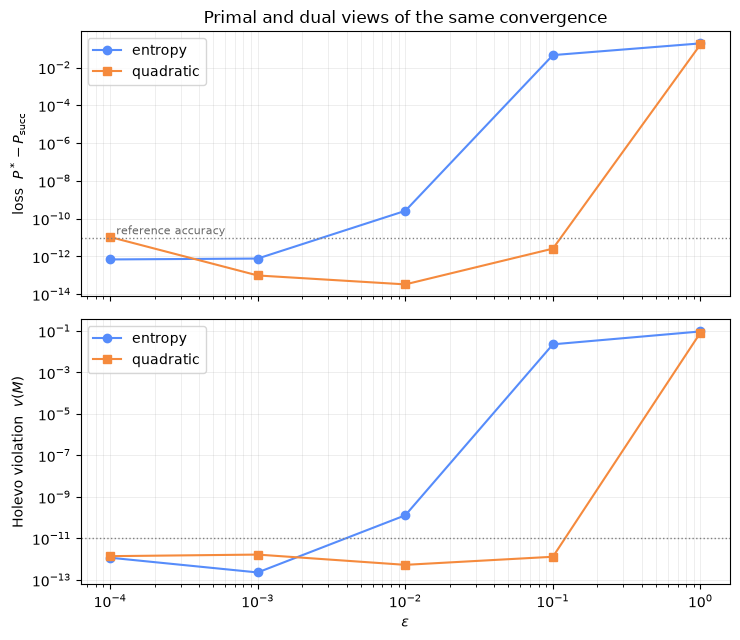

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(7.5, 6.5), sharex=True)
styles = {"entropy": dict(color="C0", marker="o"), "quadratic": dict(color="C1", marker="s")}

for name in ("entropy", "quadratic"):
    eps_ok = [e for e in EPS_GRID if runs[(name, e)]["ok"]]
    # magnitudes: below the noise floor these quantities change sign meaninglessly
    loss = [max(abs(P_star - success_probability(p, rho, runs[(name, e)]["M"])), 1e-14) for e in eps_ok]
    viol = [max(abs(holevo_violation(p, rho, runs[(name, e)]["M"])), 1e-14) for e in eps_ok]
    axes[0].loglog(eps_ok, loss, label=name, **styles[name])
    axes[1].loglog(eps_ok, viol, label=name, **styles[name])
    # say what is missing rather than let a curve simply stop
    dropped = [e for e in EPS_GRID if not runs[(name, e)]["ok"]]
    if dropped:
        axes[0].annotate(f"{name}: diverged at eps={min(dropped):g}", xy=(0.02, 0.08),
                         xycoords="axes fraction", fontsize=8, color=styles[name]["color"])

for ax in axes:
    # everything under this line is indistinguishable from zero at the reference solve's accuracy
    ax.axhline(1e-11, color="0.5", ls=":", lw=1.0)
axes[0].annotate("reference accuracy", xy=(1.1e-4, 1.5e-11), fontsize=8, color="0.4")
axes[0].set_ylabel(r"loss  $P^* - P_{\mathrm{succ}}$")
axes[1].set_ylabel(r"Holevo violation  $v(M)$")
axes[1].set_xlabel(r"$\varepsilon$")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
axes[0].set_title("Primal and dual views of the same convergence")
fig.tight_layout()
plt.show()

The two panels move together, decade for decade: whenever the recovered measurement gets closer to optimal
in objective value, its certificate violation shrinks by the same order. Neither curve stops early — with a
dual-feasible start both regularizers survive the whole grid.

The dotted line marks the accuracy of the reference value itself: SCS agrees with the closed form to
$7 \cdot 10^{-12}$, so nothing below it is a measurement of anything. Quadratic drops under it at
$\varepsilon = 10^{-1}$ and entropy at $\varepsilon = 10^{-3}$; the points that follow are not a trend but
several ways of writing zero.

## References

[1] E. Caputo, A. Gerolin, N. Monina, P. Pelikh, L. Portinale, *Quantum thermodynamics and semidefinite
programming: regularization and algorithms*, [arXiv:2602.23144](https://arxiv.org/abs/2602.23144). The
regularized primal, its unconstrained dual, and the recovery formula $M = \psi'(\cdot/\varepsilon)$ are from
this paper; quantum state discrimination is one of its semidefinite programs. Sections 3 and 4 above follow it.

[2] J. Watrous, *The Theory of Quantum Information*, Cambridge University Press, 2018,
[freely available from the author](https://cs.uwaterloo.ca/~watrous/TQI/). Everything in this notebook that
is not regularization is in Section 3.1, "Quantum state discrimination":

- Section 3.1.1, **Theorem 3.4** (Holevo–Helstrom) — the two-state closed form used to calibrate Section 1;
- Section 3.1.2 — the semidefinite program for optimal measurements and its dual;
- Section 3.1.2, **Theorem 3.9** (Holevo–Yuen–Kennedy–Lax) — the optimality condition of Section 0, which
  Watrous attributes to Holevo (1972; 1973a) and to Yuen, Kennedy and Lax (1970; 1975), and whose
  recognition as a semidefinite program he credits to Eldar, Megretski and Verghese (2003);
- Section 3.1.2, "The pretty good measurement", **eq. (3.50)** — the measurement of Section 1, so named by
  Hausladen and Wootters (1994) and one of a family introduced earlier by Belavkin (1975);
- Section 3.1.2, **Theorem 3.10** (Barnum–Knill, 2002) — the guarantee that the pretty good measurement
  succeeds with probability at least the square of the optimum.

## IMPORTANT

`spacecore` and `sdplab` are recently new libraries and are in alpha stage.
If you spotted a bug, please report an issue or send an email to pavlopelikh@gmail.com